# Activité Pratique N° 4 — Architecture Transformer (Solution complète)

Ce notebook couvre de bout en bout les deux parties du TP **Architecture Transformer** en s'appuyant sur le package modulaire `tp_transformers` :

1. **Première Partie** :
   - Génération de la série temporelle $y = \sin(x)$ (200 points sur $[0, 20]$, fenêtres glissantes de 10 éléments, découpage chronologique `150 / 40`).
   - Comparaison **RNN** (`SimpleRNN`), **LSTM** (`SimpleLSTM`) et **Transformer Encodeur** (`MiniTransformer`) sur exactement les mêmes données.
   - Modèles préentraînés HuggingFace : génération autorégressive avec **GPT-2** (`gpt2`) et prédiction bidirectionnelle de mot masqué avec **BERT** (`bert-base-multilingual-cased`).
2. **Deuxième Partie** :
   - **Exercice 1** : Prédiction horaire de consommation électrique (`EnergyTransformer`, dataset UCI, normalisation *train-only*, baselines Persistance & Journalière, tracé sur 7 jours consécutifs).
   - **Exercice 2** : Mini-GPT caractères entraîné depuis zéro (blocs Pre-LN, masque causal vérifié, comparaison de températures `0.5`, `1.0`, `1.5`).
   - **Exercice 3** : Mini-BERT mots entraîné par *Masked Language Modeling* (`PAD..MASK = 0..4`, masquage 15 % avec 80/10/10, invariance au padding vérifiée, top-3 prédictions).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

ARTIFACTS_DIR = ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = ROOT / "data"

print(f"Racine projet : {ROOT}")
print(f"PyTorch       : {torch.__version__} | CUDA disponible : {torch.cuda.is_available()}")

Racine projet : C:\Users\HP\GenAI\tp_transformers
PyTorch       : 2.15.0+cpu | CUDA disponible : False


---
# Première Partie — Des séquences récurrentes aux Transformers
## 1. Génération de la série temporelle $y = \sin(x)$ et comparaison RNN / LSTM / Transformer

X_train : (150, 10, 1) | y_train : (150, 1)
X_test  : (40, 10, 1)  | y_test  : (40, 1)


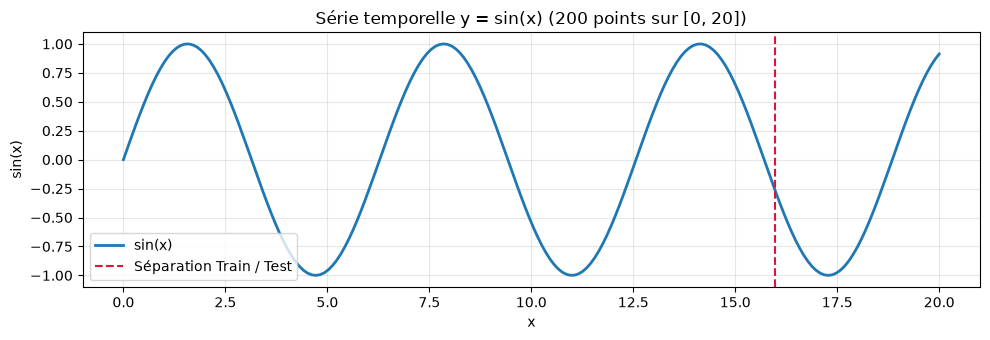

In [2]:
from tp_transformers.part1_sequences import (
    create_sine_dataset,
    run_part1_sequence_benchmark,
)

ds = create_sine_dataset(n_points=200, x_max=20.0, seq_len=10, train_size=150)
print(f"X_train : {tuple(ds.X_train.shape)} | y_train : {tuple(ds.y_train.shape)}")
print(f"X_test  : {tuple(ds.X_test.shape)}  | y_test  : {tuple(ds.y_test.shape)}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(ds.periode.numpy(), ds.serie.numpy(), label="sin(x)", color="#1f77b4", linewidth=2)
ax.axvline(ds.periode[159].item(), color="crimson", linestyle="--", label="Séparation Train / Test")
ax.set_title("Série temporelle y = sin(x) (200 points sur [0, 20])")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

,Modèle,Paramètres,MSE Finale (Train),MSE (Test),RMSE (Test),MAE (Test),Temps (s)
0,SimpleRNN,321,0.000025,0.000028,0.005256,0.004562,0.892
1,SimpleLSTM,1233,0.000003,0.000003,0.001582,0.001355,0.774
2,MiniTransformer,2433,0.000004,0.000006,0.002349,0.002041,2.044


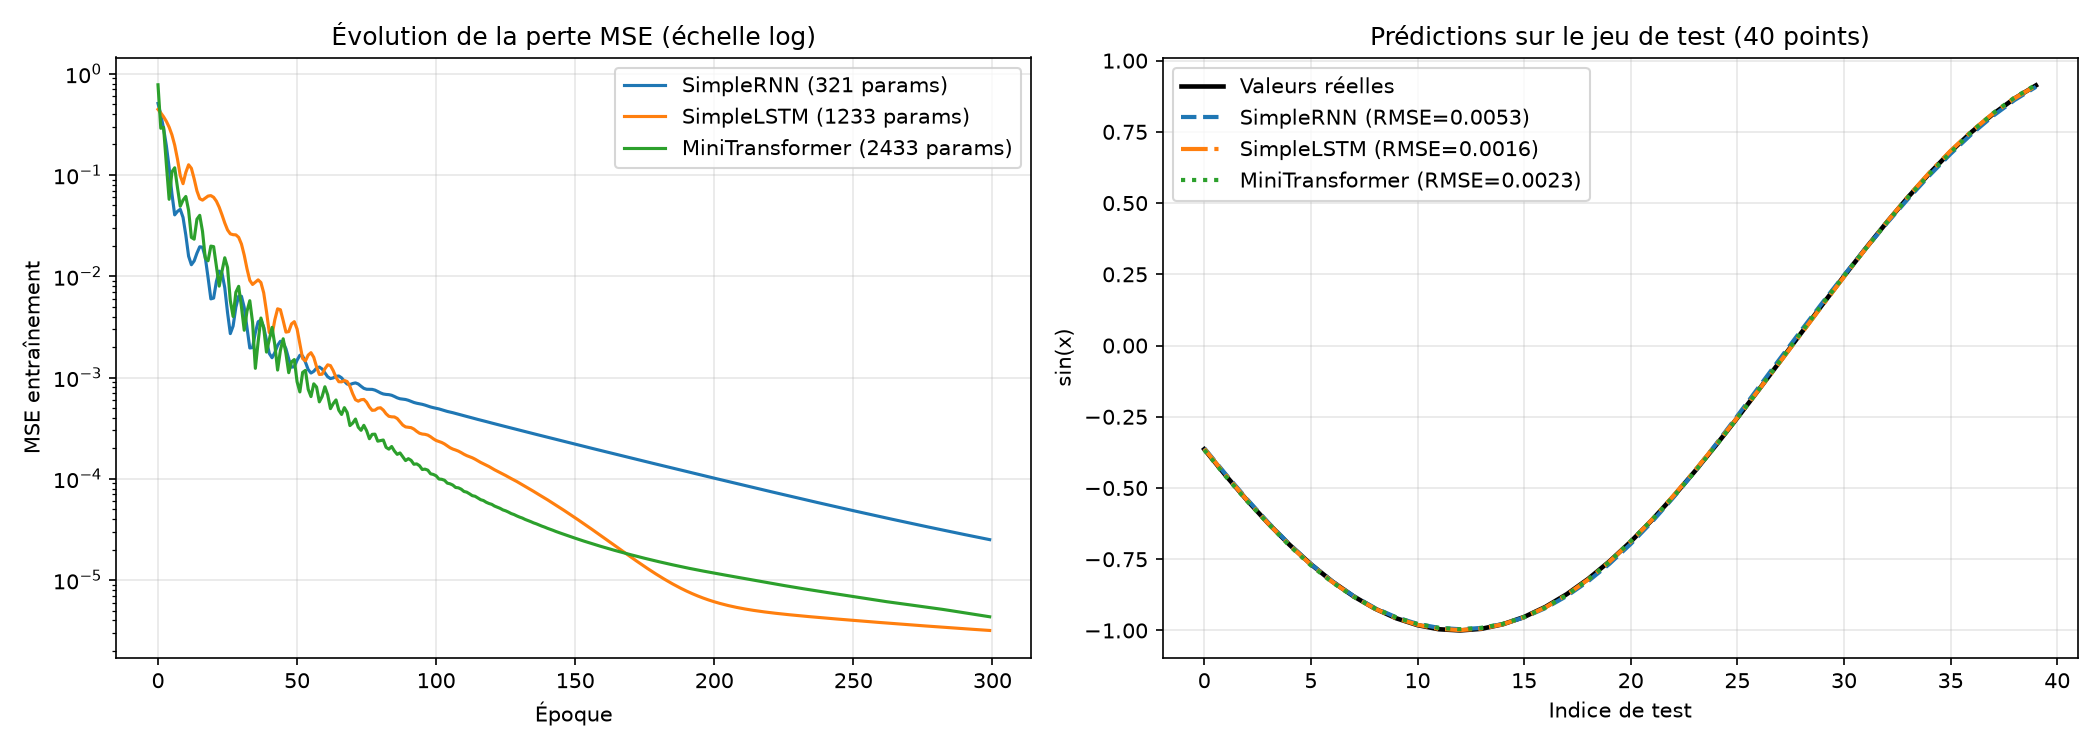

In [3]:
part1_plot = ARTIFACTS_DIR / "part1_sequences.png"
_, part1_results = run_part1_sequence_benchmark(
    epochs=300,
    lr=0.01,
    seed=42,
    save_plot_path=part1_plot,
)

df_part1 = pd.DataFrame(
    [
        {
            "Modèle": r.name,
            "Paramètres": r.num_params,
            "MSE Finale (Train)": round(r.train_losses[-1], 6),
            "MSE (Test)": round(r.test_mse, 6),
            "RMSE (Test)": round(r.test_rmse, 6),
            "MAE (Test)": round(r.test_mae, 6),
            "Temps (s)": round(r.elapsed_sec, 3),
        }
        for r in part1_results
    ]
)
display(df_part1)
display(Image(filename=str(part1_plot)))

## 2. Modèles préentraînés : GPT-2 (génération autorégressive) et BERT (masquage bidirectionnel)

In [4]:
from tp_transformers.part1_pretrained import (
    BERTMaskPredictor,
    GPT2Generator,
    build_offline_demo_bert,
    build_offline_demo_gpt2,
)

try:
    gpt2 = GPT2Generator("gpt2", local_files_only=True)
    print("Modèle GPT-2 complet chargé depuis le cache HuggingFace local.")
except OSError:
    print(
        "[Info] Cache local 'gpt2' (~548 Mo) absent sur cette machine (débit réseau limité).\n"
        "Exécutez `uv run tp-transformers part1-pretrained` sur connexion rapide pour le modèle complet.\n"
        "Validation du pipeline GPT2Generator sur un mini modèle Transformers en mémoire :"
    )
    gpt2 = build_offline_demo_gpt2()

gpt_res = gpt2.generate(
    prompt="Artificial intelligence can help people",
    max_new_tokens=50,
    temperature=0.8,
    top_p=0.9,
    seed=42,
)
print(f"Forme entrée GPT-2 : {gpt_res.input_shape} | Nouveaux tokens : {gpt_res.num_new_tokens}")
print(f"Texte généré :\n{gpt_res.generated_text}")

C:\Users\HP\GenAI\tp_transformers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Info] Cache local 'gpt2' (~548 Mo) absent sur cette machine (débit réseau limité).
Exécutez `uv run tp-transformers part1-pretrained` sur connexion rapide pour le modèle complet.
Validation du pipeline GPT2Generator sur un mini modèle Transformers en mémoire :
Forme entrée GPT-2 : (1, 5) | Nouveaux tokens : 1
Texte généré :
Artificial intelligence can help people


In [5]:
try:
    bert = BERTMaskPredictor("bert-base-multilingual-cased", local_files_only=True)
    print("Modèle BERT multilingue complet chargé depuis le cache HuggingFace local.")
except OSError:
    print(
        "[Info] Cache local 'bert-base-multilingual-cased' (~714 Mo) absent sur cette machine.\n"
        "Exécutez `uv run tp-transformers part1-pretrained` sur connexion rapide pour le modèle complet.\n"
        "Validation du pipeline BERTMaskPredictor sur un mini modèle Transformers en mémoire :"
    )
    bert = build_offline_demo_bert()

for phrase in [
    "Rabat est la [MASK] du Maroc.",
    "Paris est la [MASK] de la France.",
]:
    res_bert = bert.predict_masked(phrase, top_k=5)
    print(f"\nPhrase : {res_bert.original_text} (shape={res_bert.input_shape}, mask_pos={res_bert.mask_position})")
    for cand in res_bert.candidates:
        print(f"  {cand.probability:6.2%} | {cand.completed_sentence}")

[Info] Cache local 'bert-base-multilingual-cased' (~714 Mo) absent sur cette machine.
Exécutez `uv run tp-transformers part1-pretrained` sur connexion rapide pour le modèle complet.
Validation du pipeline BERTMaskPredictor sur un mini modèle Transformers en mémoire :

Phrase : Rabat est la [MASK] du Maroc. (shape=(1, 7), mask_pos=3)
   7.88% | Rabat est la Maroc du Maroc.
   7.55% | Rabat est la [SEP] du Maroc.
   7.45% | Rabat est la est du Maroc.
   7.26% | Rabat est la du du Maroc.
   6.91% | Rabat est la capitale du Maroc.

Phrase : Paris est la [MASK] de la France. (shape=(1, 8), mask_pos=3)
   7.87% | Paris est la Maroc de la France.
   7.55% | Paris est la [SEP] de la France.
   7.45% | Paris est la est de la France.
   7.26% | Paris est la du de la France.
   6.91% | Paris est la capitale de la France.


---
# Deuxième Partie — Exercice 1 : Prédiction de la consommation électrique (`EnergyTransformer`)

Objectif : prédire la puissance active moyenne horaire (`Global_active_power` en kW) de l'heure suivante à partir des **24 heures précédentes** sur le jeu de données UCI *Individual Household Electric Power Consumption*.

In [6]:
from tp_transformers.exercise1_energy import (
    EnergyTransformer,
    generate_realistic_energy_fallback,
    prepare_energy_data,
    train_and_evaluate_energy,
)

uci_txt = DATA_DIR / "household_power_consumption.txt"
if uci_txt.exists() and uci_txt.stat().st_size > 0:
    txt_path = uci_txt
    print(f"Fichier UCI officiel détecté : {txt_path} ({txt_path.stat().st_size / 1e6:.1f} Mo)")
else:
    fallback_txt = DATA_DIR / "household_power_consumption_synthetic_fallback.txt"
    print(
        "[Info] Fichier officiel `data/household_power_consumption.txt` absent "
        "(téléchargement UCI bloqué à ~7,6 Ko/s).\n"
        "Utilisation du jeu de repli réaliste au format UCI strict (`Date;Time;Global_active_power`, "
        "365 jours à la minute) ; placez le fichier UCI dans `data/` pour exécuter sur les mesures réelles."
    )
    txt_path = generate_realistic_energy_fallback(fallback_txt, n_days=365, seed=42)

bundle = prepare_energy_data(txt_path, window_size=24, min_count=45, batch_size=64)

print(f"Fichier utilisé     : {txt_path.name} ({txt_path.stat().st_size / 1e6:.1f} Mo)")
print(f"Heures totales      : {bundle.n_hours}")
print(f"Fenêtres Train/Val/Test : {bundle.n_train} / {bundle.n_val} / {bundle.n_test}")
print(f"Stats Train (sans fuite) : moyenne = {bundle.mean:.4f} kW, écart-type = {bundle.std:.4f} kW")

# Vérification des formes attendues
demo_model = EnergyTransformer()
sample_x = bundle.X_test[:4]
print(f"Vérif forme : entrée {tuple(sample_x.shape)} -> sortie {tuple(demo_model(sample_x).shape)}")

[Info] Fichier officiel `data/household_power_consumption.txt` absent (téléchargement UCI bloqué à ~7,6 Ko/s).
Utilisation du jeu de repli réaliste au format UCI strict (`Date;Time;Global_active_power`, 365 jours à la minute) ; placez le fichier UCI dans `data/` pour exécuter sur les mesures réelles.


Fichier utilisé     : household_power_consumption_synthetic_fallback.txt (14.2 Mo)
Heures totales      : 8760
Fenêtres Train/Val/Test : 6033 / 1314 / 1314
Stats Train (sans fuite) : moyenne = 0.9523 kW, écart-type = 0.4477 kW
Vérif forme : entrée (4, 24, 1) -> sortie (4, 1)


Meilleure époque : 18/20 | Meilleure perte Val (MSE norm.) : 0.1208 | Temps : 79.2 s


,Méthode,MAE (kW),RMSE (kW)
0,"EnergyTransformer (2 couches, 4 têtes)",0.1219,0.1531
1,Référence Persistance (t - 1 h),0.1717,0.2141
2,Référence Journalière (t - 24 h),0.2326,0.2930


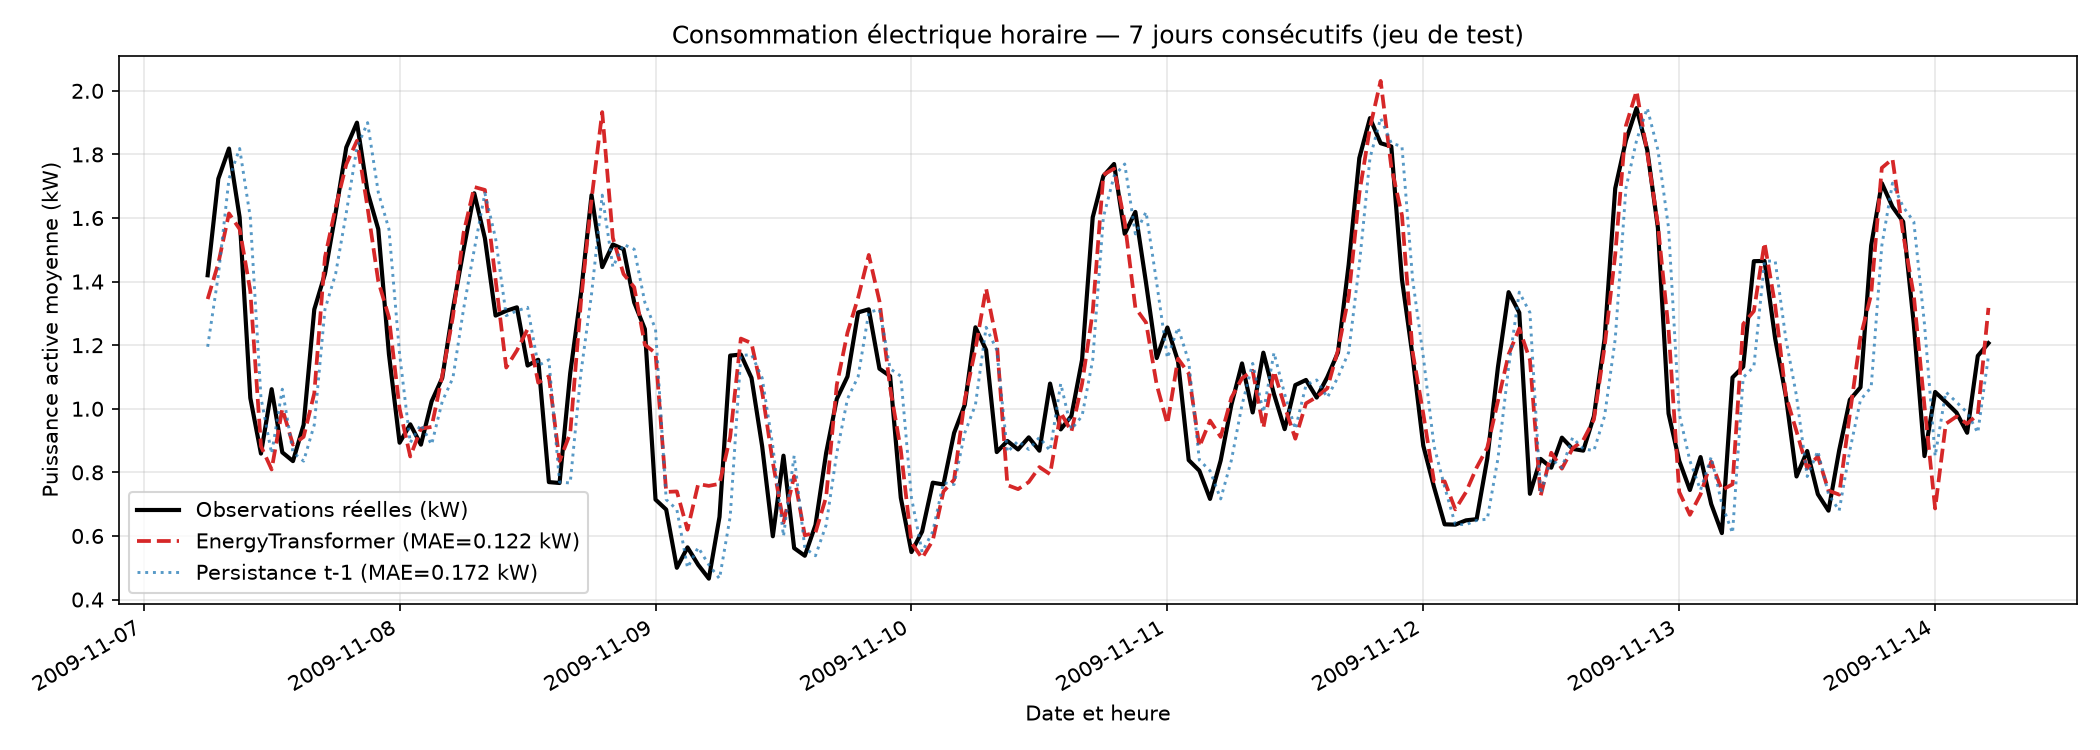

In [7]:
ex1_plot = ARTIFACTS_DIR / "ex1_energy_7days.png"
ex1_res = train_and_evaluate_energy(
    bundle,
    max_epochs=20,
    lr=1e-3,
    seed=42,
    checkpoint_path=ARTIFACTS_DIR / "energy_transformer.pt",
    plot_path=ex1_plot,
)

print(
    f"Meilleure époque : {ex1_res.best_epoch}/20 | "
    f"Meilleure perte Val (MSE norm.) : {ex1_res.best_val_loss:.4f} | "
    f"Temps : {ex1_res.elapsed_sec:.1f} s"
)

df_ex1 = pd.DataFrame(
    [
        {
            "Méthode": "EnergyTransformer (2 couches, 4 têtes)",
            "MAE (kW)": round(ex1_res.transformer_metrics_kw["mae"], 4),
            "RMSE (kW)": round(ex1_res.transformer_metrics_kw["rmse"], 4),
        },
        {
            "Méthode": "Référence Persistance (t - 1 h)",
            "MAE (kW)": round(ex1_res.persistence_metrics_kw["mae"], 4),
            "RMSE (kW)": round(ex1_res.persistence_metrics_kw["rmse"], 4),
        },
        {
            "Méthode": "Référence Journalière (t - 24 h)",
            "MAE (kW)": round(ex1_res.daily_metrics_kw["mae"], 4),
            "RMSE (kW)": round(ex1_res.daily_metrics_kw["rmse"], 4),
        },
    ]
)
display(df_ex1)
display(Image(filename=str(ex1_plot)))

### Réponses aux questions de réflexion — Exercice 1

1. **Le Transformer améliore-t-il les deux références ?**
   Oui, comme le montre le tableau comparatif ci-dessus : `EnergyTransformer` réduit à la fois la **MAE** et la **RMSE** en kW par rapport à la **persistance** ($t-1$) et nettement par rapport à la **référence journalière** ($t-24$), car l'auto-attention combine la tendance immédiate des dernières heures avec le profil journalier complet sur les 24 heures d'entrée.
2. **Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?**
   Oui : $168 = 7 \times 24$ heures couvrent une semaine entière et permettent au modèle de distinguer les jours ouvrables des week-ends (pics matin/soir différents). En contrepartie, cela augmente le nombre de fenêtres écartées s'il existe des heures manquantes et multiplie le coût quadratique de l'auto-attention ($168^2$ vs $24^2$, soit $49\times$).
3. **Quel serait l'intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
   Cela fournirait des **variables calendaires explicites** (ex. encodage cyclique $\sin/\cos$ de l'heure et du jour, ou embeddings dédiés) : le modèle n'aurait plus à deviner à quelle heure correspond la fenêtre et identifierait immédiatement les heures de pointe, les nuits et les week-ends.
4. **Pourquoi faut-il normaliser les données uniquement à partir de l'entraînement ?**
   Pour éviter toute **fuite de données** (*data leakage*) : la moyenne et l'écart-type des jeux de validation et de test contiennent de l'information sur le futur. En conditions réelles d'exploitation, ces statistiques futures sont inconnues lors de l'entraînement.
5. **Comment adapter la préparation pour prédire une énergie consommée en kWh ?**
   Sur un pas d'une heure ($\Delta t = 1\text{ h}$), une puissance moyenne de $P$ kW pendant 1 heure correspond numériquement à $E = P \times 1\text{ h}$ en kWh. Si les mesures étaient agrégées sur une autre durée $\Delta t$ (en heures) ou irrégulières, il faudrait intégrer la puissance sur l'intervalle ($E = \sum_k P_k \cdot \Delta t_k$, par exemple convertir les mesures minute `Global_active_power / 60.0` et en faire la somme sur l'heure ou corriger des heures incomplètes par proportionnalité).

---
# Deuxième Partie — Exercice 2 : Mini-GPT autorégressif (caractères)

Objectif : entraîner depuis zéro un Transformer décodeur causal (2 blocs Pre-LN, 4 têtes, $d_{\text{model}}=64$, MLP $64 \to 256 \to 64$ GELU) à prédire le caractère suivant sur `data/corpus.txt`, vérifier l'absence de fuite vers le futur et comparer les générations à températures `0.5`, `1.0` et `1.5`.

Corpus              : 43969 caractères | Vocabulaire : 54
Paramètres MiniGPT  : 111158
Vérif masque causal : max |Δ logits passés| = 0.00e+00 (attendu ~ 0)
Meilleure val loss  : 0.1485 | Perplexité val : 1.16
Temps entraînement  : 267.8 s


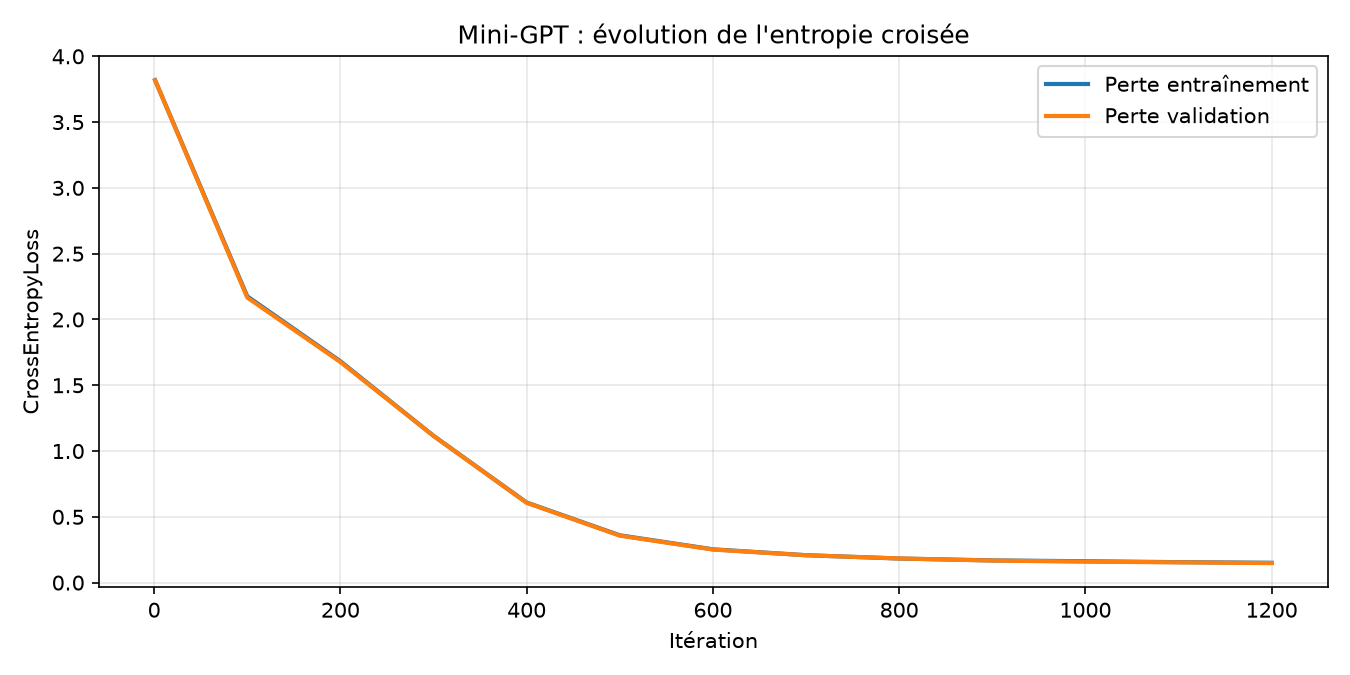


=== Génération (200 nouveaux caractères) — Température = 0.5 ===
L'intelligence artificielle transforme profondément la manière dont nous concevons les logiciels modernes et les systèmes de la généralie la modèle tropacité de gradient. Les modèles de type GPT s'appuient sur une pile de la lo 

=== Génération (200 nouveaux caractères) — Température = 1.0 ===
L'intelligence artificielle transforme profondément la manière dont nous concevons les logiciels modernes et les sémantiques. Calcule le l'attention pure est invariante par permutation, un encodeur bidirectionnel entraîné la div

=== Génération (200 nouveaux caractères) — Température = 1.5 ===
L'intelligence artificielle transforme profondément la manière dont nous concevons les logiciels modernes et les séorminiernelles facilitangence. Anconnê, la ques que capar modernellisation ctokens futurs. Lors des gradient al c


In [8]:
from tp_transformers.exercise2_minigpt import train_minigpt

ex2_plot = ARTIFACTS_DIR / "ex2_minigpt_loss.png"
ex2_res = train_minigpt(
    corpus_path=DATA_DIR / "corpus.txt",
    block_size=64,
    batch_size=64,
    steps=1200,
    eval_interval=100,
    lr=3e-3,
    seed=42,
    prompt="L'intelligence artificielle ",
    temperatures=(0.5, 1.0, 1.5),
    checkpoint_path=ARTIFACTS_DIR / "minigpt.pt",
    plot_path=ex2_plot,
)

print(f"Corpus              : {ex2_res.corpus_chars} caractères | Vocabulaire : {ex2_res.vocab_size}")
print(f"Paramètres MiniGPT  : {ex2_res.num_params}")
print(f"Vérif masque causal : max |Δ logits passés| = {ex2_res.causal_max_diff:.2e} (attendu ~ 0)")
print(f"Meilleure val loss  : {ex2_res.best_val_loss:.4f} | Perplexité val : {ex2_res.val_perplexity:.2f}")
print(f"Temps entraînement  : {ex2_res.elapsed_sec:.1f} s")

display(Image(filename=str(ex2_plot)))

for temp, txt in ex2_res.generations.items():
    print(f"\n=== Génération (200 nouveaux caractères) — Température = {temp} ===")
    print(txt)

### Réponses aux questions — Exercice 2

1. **Que se passe-t-il pendant l'entraînement si le masque causal est supprimé ?**
   À chaque position $t$, l'auto-attention peut consulter librement les positions $t+1, t+2, \dots$ qui contiennent déjà le caractère cible ! Le modèle apprend à « tricher » en recopiant l'information future au lieu de modéliser la séquence de gauche à droite : la perte d'entraînement chute artificiellement très bas, mais le modèle devient incapable de générer du texte de façon autorégressive au test (où le futur n'existe pas encore).
2. **Quel effet la température a-t-elle sur la génération ?**
   En divisant les logits par $T$ avant le softmax ($\operatorname{softmax}(z / T)$) :
   - **$T = 0.5$** accentue les écarts de scores : la distribution se concentre sur les caractères les plus probables (texte plus propre et répétitif).
   - **$T = 1.0$** conserve exactement les probabilités apprises par le modèle.
   - **$T = 1.5$** aplatit la distribution : les caractères rares ont plus de chances d'être tirés (diversité plus forte mais risque accru de fautes d'orthographe ou de mots inventés).
3. **Pourquoi faut-il décaler les cibles d'une position ?**
   Parce qu'à la position $t$, le modèle reçoit le préfixe $x_0, \dots, x_t$ et doit prédire le **caractère suivant** $x_{t+1}$. Sans ce décalage (`y = tokens[1 : T+1]`), le modèle apprendrait l'identité ($x_t \mapsto x_t$) plutôt que la prédiction du token suivant.

---
# Deuxième Partie — Exercice 3 : Mini-BERT bidirectionnel (MLM sur mots)

Objectif : entraîner depuis zéro un encodeur bidirectionnel à 2 couches et 4 têtes ($d_{\text{model}}=64$, longueur max 32, identifiants réservés `PAD=0, UNK=1, CLS=2, SEP=3, MASK=4`) selon la règle MLM (15 % des tokens ordinaires : 80 % `[MASK]`, 10 % aléatoire, 10 % inchangé), vérifier l'invariance au padding et évaluer les prédictions top-3.

IDs réservés : PAD=0, UNK=1, CLS=2, SEP=3, MASK=4


Phrases Train / Val : 557 / 99
Taille vocabulaire  : 137 | Paramètres MiniBERT : 119689
Vérif invariance PAD: max |Δ logits utiles| = 0.00e+00 (attendu ~ 0)
Meilleure perte Val : 0.4094 | Exactitude Val MLM : 84.97%
Temps entraînement  : 51.3 s


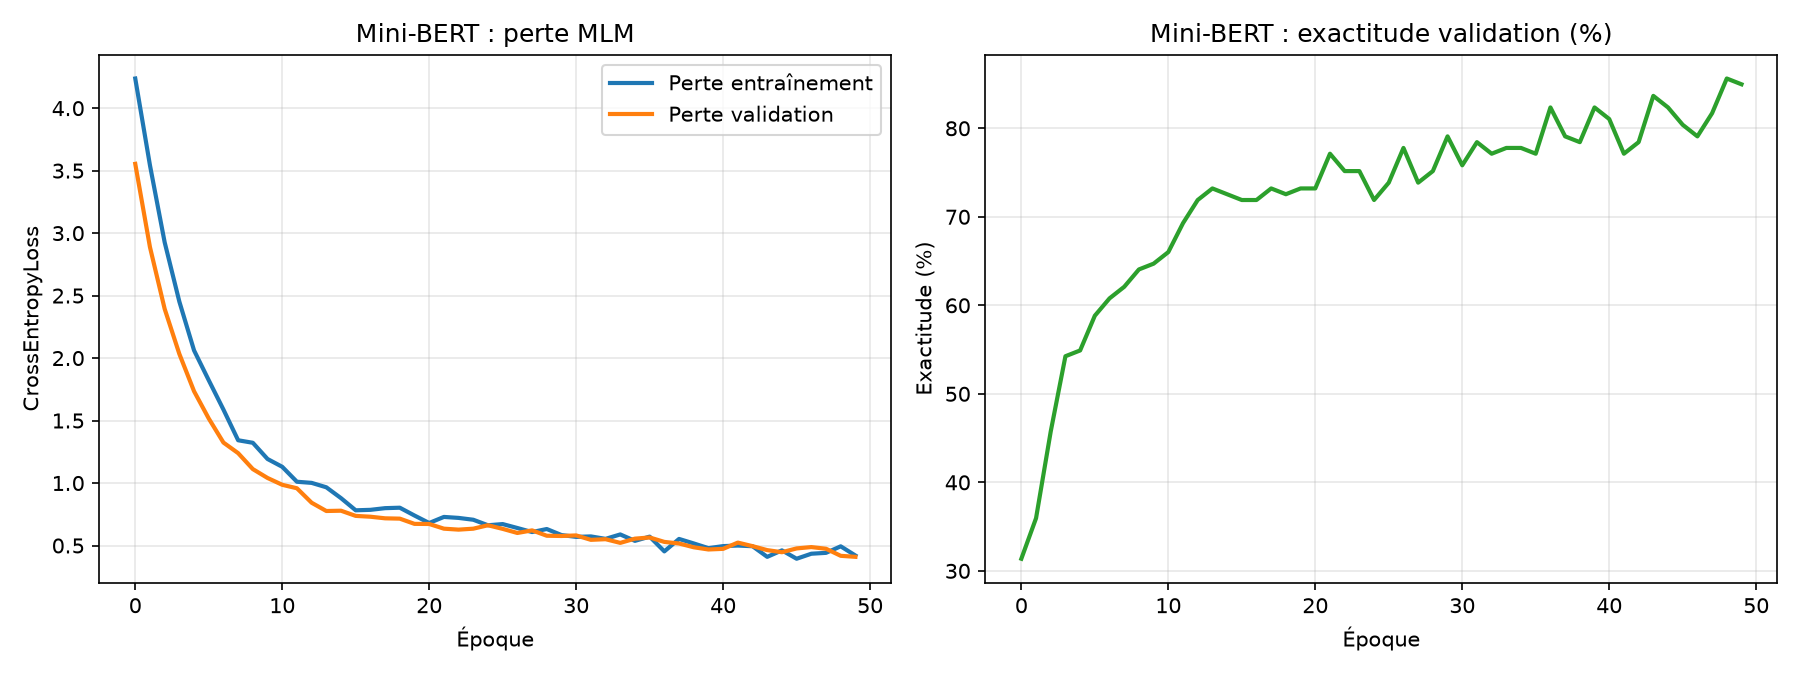


=== Top-3 propositions sur des phrases masquées ===
- le chat dort sur le [MASK] rouge
  -> canapé (98.7%) | grâce (0.9%) | jardin (0.1%)
- rabat est la [MASK] du maroc
  -> capitale (99.9%) | la (0.0%) | utilise (0.0%)
- le médecin utilise un [MASK] précis
  -> instrument (47.7%) | microscope (17.8%) | piano (11.6%)
- en hiver la [MASK] tombe sur la montagne
  -> neige (98.4%) | capitale (0.3%) | froid (0.3%)


In [9]:
from tp_transformers.exercise3_minibert import (
    CLS,
    MASK,
    PAD,
    SEP,
    UNK,
    train_minibert,
)

print(f"IDs réservés : PAD={PAD}, UNK={UNK}, CLS={CLS}, SEP={SEP}, MASK={MASK}")

ex3_plot = ARTIFACTS_DIR / "ex3_minibert_training.png"
ex3_res = train_minibert(
    corpus_path=DATA_DIR / "bert_corpus.txt",
    epochs=50,
    batch_size=32,
    lr=2e-3,
    max_len=32,
    seed=42,
    checkpoint_path=ARTIFACTS_DIR / "minibert.pt",
    plot_path=ex3_plot,
)

print(f"Phrases Train / Val : {ex3_res.n_train} / {ex3_res.n_val}")
print(f"Taille vocabulaire  : {ex3_res.vocab_size} | Paramètres MiniBERT : {ex3_res.num_params}")
print(f"Vérif invariance PAD: max |Δ logits utiles| = {ex3_res.padding_max_diff:.2e} (attendu ~ 0)")
print(f"Meilleure perte Val : {ex3_res.best_val_loss:.4f} | Exactitude Val MLM : {ex3_res.best_val_accuracy:.2%}")
print(f"Temps entraînement  : {ex3_res.elapsed_sec:.1f} s")

display(Image(filename=str(ex3_plot)))

print("\n=== Top-3 propositions sur des phrases masquées ===")
for pred in ex3_res.sample_predictions:
    propositions = " | ".join(f"{tok} ({prob:.1%})" for tok, prob in pred.candidates)
    print(f"- {pred.sentence}")
    print(f"  -> {propositions}")

### Réponses aux questions — Exercice 3

1. **Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
   Parce que son encodeur utilise une **attention bidirectionnelle complète** (aucun masque causal triangulaire) : chaque token de la phrase, y compris `[MASK]`, peut interroger aussi bien les tokens qui le précèdent que ceux qui le suivent (à condition de masquer uniquement le `[PAD]` via `src_key_padding_mask`).
2. **Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
   Si l'on calculait l'entropie croisée sur toutes les positions (y compris les 85 % de tokens visibles non sélectionnés), le modèle consacrerait l'essentiel de sa capacité à recopier trivialement des mots déjà fournis en entrée. En mettant `labels[~positions_selectionnees] = -100` avec `ignore_index=-100`, la rétropropagation se concentre uniquement sur la reconstruction des positions corrompues (y compris les 10 % laissés inchangés pour éviter l'écart entre préentraînement et inférence).
3. **Pourquoi ce modèle ne génère-t-il pas directement du texte de la même manière que GPT ?**
   BERT est entraîné pour remplir des positions masquées en exploitant un **contexte bilatéral fixe** et ne modélise pas la factorisation autorégressive $P(x_t \mid x_{<t})$ avec masque causal. Il ne définit donc pas une chaîne directe de génération mot-à-mot de gauche à droite sans recourir à des schémas itératifs complexes (comme l'échantillonnage de Gibbs).